# Build an evidence brief, not a risk score

**Objective:** Produce a reproducible study-area brief with explicit data boundaries, a real observation figure and an acquisition plan for the next question.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

A useful One Health brief connects a decision to evidence and its limits. Start by choosing a smaller bounding box inside the loaded package. Report what was observed, when and at what spatial support. Separate facts, assumptions and unanswered questions. No intervention outcomes, health-risk scores or probabilities can be estimated from this package alone.

To explore another bounded U.S. area, use **Create profile from live sources** in the explorer or `scripts/acquire_data.py --bbox ... --output ...` in a local acquisition environment. Export the package and keep its scene identity, Census query, dates and formulas. This notebook uses the bundled, independently verified starter rather than silently replacing it with live values.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=10_capstone.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
w,s,e,n = manifest["bbox"]
# EDIT these bounds within the loaded Fresno snapshot.
study_bbox = [w+.04, s+.04, e-.04, n-.04]
assert w <= study_bbox[0] < study_bbox[2] <= e and s <= study_bbox[1] < study_bbox[3] <= n
selected = [r for r in data if study_bbox[0] <= r["lon"] <= study_bbox[2] and study_bbox[1] <= r["lat"] <= study_bbox[3]]
assert selected
report = {"bbox":study_bbox, "scene_id":manifest["scene_id"], "satellite_datetime":manifest["satellite_datetime"],
          "population_reference":manifest["population_date"], "selected_samples":len(selected),
          "mean_sample_ndvi":avg("ndvi",selected), "mean_sample_surface_c":avg("temperature_c",selected),
          "limits":["Systematic samples, not full-resolution area means", "Surface is not air temperature", "No health outcomes or animal observations"]}
print(json.dumps(report,indent=2))
Path("my-evidence-brief.json").write_text(json.dumps(report,indent=2))

{
  "bbox": [
    -119.86,
    36.69,
    -119.69000000000001,
    36.86
  ],
  "scene_id": "LC09_L2SP_042035_20240830_02_T1",
  "satellite_datetime": "2024-08-30T18:33:53.353894Z",
  "population_reference": "2020-04-01",
  "selected_samples": 3178,
  "mean_sample_ndvi": 0.27940307781623663,
  "mean_sample_surface_c": 44.711140075707995,
  "limits": [
    "Systematic samples, not full-resolution area means",
    "Surface is not air temperature",
    "No health outcomes or animal observations"
  ]
}


503

## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

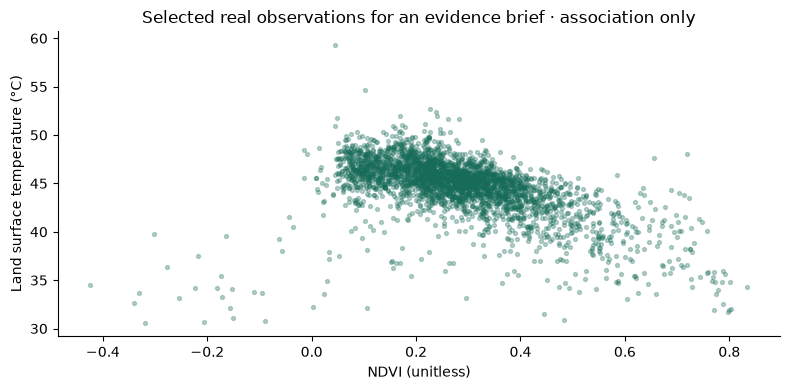

In [3]:
paired = [r for r in selected if r["ndvi"] is not None and r["temperature_c"] is not None]
plt.scatter([r["ndvi"] for r in paired], [r["temperature_c"] for r in paired], s=8, alpha=.3, color="#176c59")
plt.xlabel("NDVI (unitless)"); plt.ylabel("Land surface temperature (°C)")
plt.title("Selected real observations for an evidence brief · association only")
plt.tight_layout(); plt.show()

## Interpret and extend

Write a 300-word brief: decision and partners; observed evidence and dates; population interpretation; missing measurements; next acquisition; and a statement of what cannot be concluded. Download the JSON and your edited notebook from JupyterLite before clearing browser storage.

## Sources and attribution

- [CDC, About One Health](https://www.cdc.gov/one-health/about/index.html).
- [WHO, One Health](https://www.who.int/health-topics/one-health).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.